# Quick Commerce Data Analyasis

#==============================

This is a synthetic Quick Commerce (Q-Commerce) dataset simulating real-world order data from platforms like Blinkit, Zepto, Swiggy Instamart, and others.

It contains order-level features such as city, category, delivery time, ratings, discounts, and revenue. It is ideal for practicing data cleaning, exploratory data analysis (EDA), data visualization, dashboard building, and extracting business insights.

In [2]:
# Importing python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [3]:
# load the data

from google.colab import files

uploaded= files.upload()

Saving quick_commerce_data_raw.csv to quick_commerce_data_raw (1).csv


In [4]:
df = pd.read_csv("quick_commerce_data_raw.csv")

In [5]:
df.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.33750,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2
1,1000002,Flipkart Minutes,Amritsar,56,1007.30000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,NaN,Personal Care,Cash on Delivery,3.3,0,3.8
3,1000004,Swiggy Instamart,Delhi,23,1179.05925,5.864,6.44,2.0,Dairy,Credit Card,5.0,1,5.0
4,1000005,Dunzo,Mumbai,44,586.02550,12.470,2.45,13.0,Household,Wallet,3.7,0,4.8


In [6]:
# dataset inspection
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   Order_ID                 1000000 non-null  int64  
 1   Company                  1000000 non-null  object 
 2   City                     948000 non-null   object 
 3   Customer_Age             1000000 non-null  int64  
 4   Order_Value              1000000 non-null  float64
 5   Delivery_Time_Min        1000000 non-null  float64
 6   Distance_Km              1000000 non-null  float64
 7   Items_Count              965000 non-null   float64
 8   Product_Category         1000000 non-null  object 
 9   Payment_Method           1000000 non-null  object 
 10  Customer_Rating          953000 non-null   float64
 11  Discount_Applied         1000000 non-null  int64  
 12  Delivery_Partner_Rating  895863 non-null   float64
dtypes: float64(6), int64(3), object(4)
memory u

In [7]:
# summary Statistics

df.describe()

,Order_ID,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
count,1.000000e+06,1000000.000000,1000000.000000,1000000.000000,1000000.000000,965000.000000,953000.000000,1000000.000000,895863.000000
mean,1.500000e+06,38.470387,571.643584,16.452412,7.750231,9.998317,3.042072,0.400883,3.749257
std,2.886753e+05,12.118520,382.784520,6.257172,4.186665,5.478725,1.186872,0.490078,0.722121
min,1.000001e+06,18.000000,50.000000,5.000000,0.500000,1.000000,1.000000,0.000000,2.500000
25%,1.250001e+06,28.000000,287.840150,12.368000,4.130000,5.000000,2.000000,0.000000,3.100000
50%,1.500000e+06,38.000000,531.324600,16.342000,7.740000,10.000000,3.000000,0.000000,3.700000
75%,1.750000e+06,49.000000,796.182500,20.196000,11.380000,15.000000,4.000000,1.000000,4.400000
max,2.000000e+06,59.000000,13877.325000,40.000000,15.000000,19.000000,5.000000,1.000000,5.000000


In [8]:
# checking null value

df.isna().sum()

,0
Order_ID,0
Company,0
City,52000
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,35000
Product_Category,0
Payment_Method,0


In [9]:
# to show the records which contains any or all null values

df[df.isna().any(axis=1)]

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,NaN,Personal Care,Cash on Delivery,3.3,0,3.8
6,1000007,Blinkit,Bengluru,37,516.86480,18.476,12.46,19.0,Snacks,Debit Card,2.8,0,NaN
17,1000018,Zepto,Delhi,23,1041.42975,5.000,14.74,18.0,Snacks,Wallet,NaN,1,NaN
21,1000022,Blinkit,NaN,41,716.89860,17.804,11.34,7.0,Beverages,Credit Card,2.7,1,3.6
22,1000023,Jio Mart,Delhi,48,50.00000,8.498,0.83,3.0,Snacks,Cash on Delivery,3.1,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999966,1999967,Dunzo,NaN,39,783.89250,18.820,14.70,NaN,Household,Wallet,3.1,1,4.9
999975,1999976,Amazon Now,Bengluru,34,515.89380,21.294,10.49,10.0,Fruits & Vegetables,Wallet,NaN,1,3.0
999981,1999982,Amazon Now,NaN,33,939.34470,21.080,11.80,18.0,Dairy,Wallet,3.2,1,4.4
999983,1999984,Swiggy Instamart,Hyderabad,42,50.00000,13.386,2.31,2.0,Groceries,Wallet,NaN,0,3.2


In [10]:
df[df.isna().all(axis=1)]

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating


In [11]:
# Remove rows having null valus

df=df.dropna(subset=['City'])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 948000 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 948000 non-null  int64  
 1   Company                  948000 non-null  object 
 2   City                     948000 non-null  object 
 3   Customer_Age             948000 non-null  int64  
 4   Order_Value              948000 non-null  float64
 5   Delivery_Time_Min        948000 non-null  float64
 6   Distance_Km              948000 non-null  float64
 7   Items_Count              914772 non-null  float64
 8   Product_Category         948000 non-null  object 
 9   Payment_Method           948000 non-null  object 
 10  Customer_Rating          903425 non-null  float64
 11  Discount_Applied         948000 non-null  int64  
 12  Delivery_Partner_Rating  849306 non-null  float64
dtypes: float64(6), int64(3), object(4)
memory usage: 101.3+ MB


In [12]:
# filling Missing values with mode

x= df['Items_Count'].mode()
x

,Items_Count
0,19.0


In [13]:
df['Items_Count']=df['Items_Count'].fillna(x[0])

In [14]:
df.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


In [15]:
# fill null values with group wise mean/median

df['Customer_Rating']=df.groupby('Company')["Customer_Rating"].transform(lambda X:X.fillna(X.mean()))
df['Delivery_Partner_Rating']=df.groupby('Delivery_Time_Min')["Delivery_Partner_Rating"].transform(lambda y:y.fillna(y.mean()))

In [16]:
df.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


In [17]:
df['Delivery_Partner_Rating']=df['Delivery_Partner_Rating'].fillna(df['Delivery_Partner_Rating'].mean())

In [18]:
df.isna().sum()

,0
Order_ID,0
Company,0
City,0
Customer_Age,0
Order_Value,0
Delivery_Time_Min,0
Distance_Km,0
Items_Count,0
Product_Category,0
Payment_Method,0


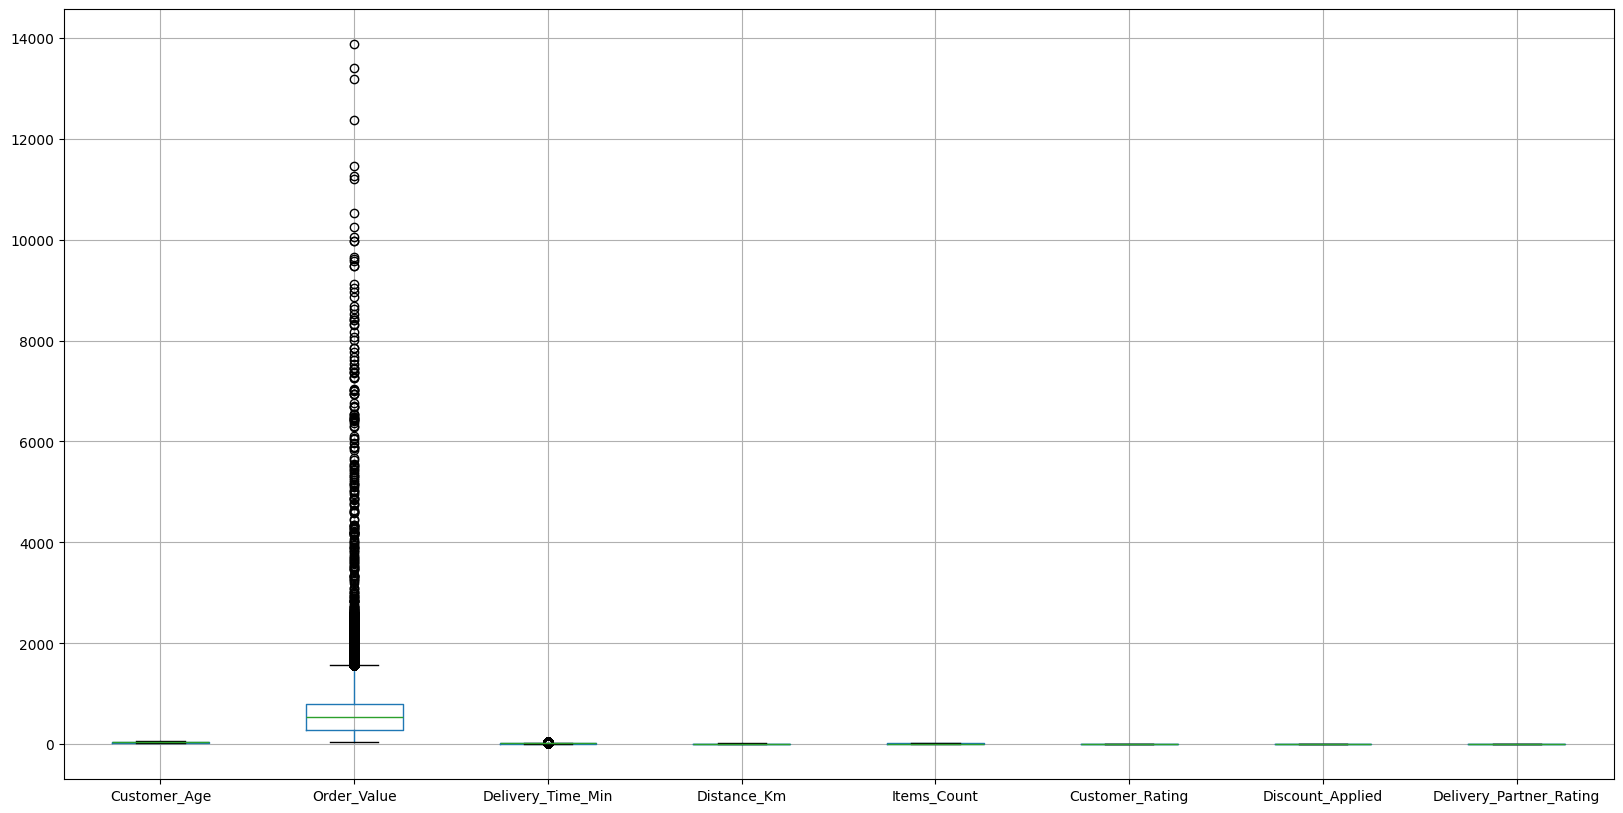

In [19]:
# remove Outliers

# Box plot

plt.figure(figsize=(20,10))

df.drop(columns=['Order_ID']).boxplot()
plt.show()

In [20]:
#  percentile (Capping) method (used in industry)

# df['Order_Value'] =df['Order_Value'].clip(upper=2500)

In [21]:
# Filttering method

df= df[df['Order_Value']<=2500]

In [22]:
df

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.33750,19.182,11.97,12.0,Dairy,Wallet,2.1,1,3.2
1,1000002,Flipkart Minutes,Amritsar,56,1007.30000,19.644,12.74,10.0,Snacks,Cash on Delivery,2.3,0,3.2
2,1000003,Flipkart Minutes,Mumbai,18,1211.66000,16.910,4.85,19.0,Personal Care,Cash on Delivery,3.3,0,3.8
3,1000004,Swiggy Instamart,Delhi,23,1179.05925,5.864,6.44,2.0,Dairy,Credit Card,5.0,1,5.0
4,1000005,Dunzo,Mumbai,44,586.02550,12.470,2.45,13.0,Household,Wallet,3.7,0,4.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...
999995,1999996,Big Basket,Mumbai,48,72.33000,17.806,3.01,19.0,Fruits & Vegetables,Wallet,4.2,0,2.8
999996,1999997,Swiggy Instamart,Mumbai,33,1509.66300,18.306,10.51,9.0,Beverages,Debit Card,4.1,1,3.5
999997,1999998,Jio Mart,Noida,29,637.32300,17.590,2.65,6.0,Groceries,Cash on Delivery,3.4,0,4.6
999998,1999999,Dunzo,Pune,42,1103.12100,12.656,7.76,12.0,Snacks,Wallet,4.0,1,4.5


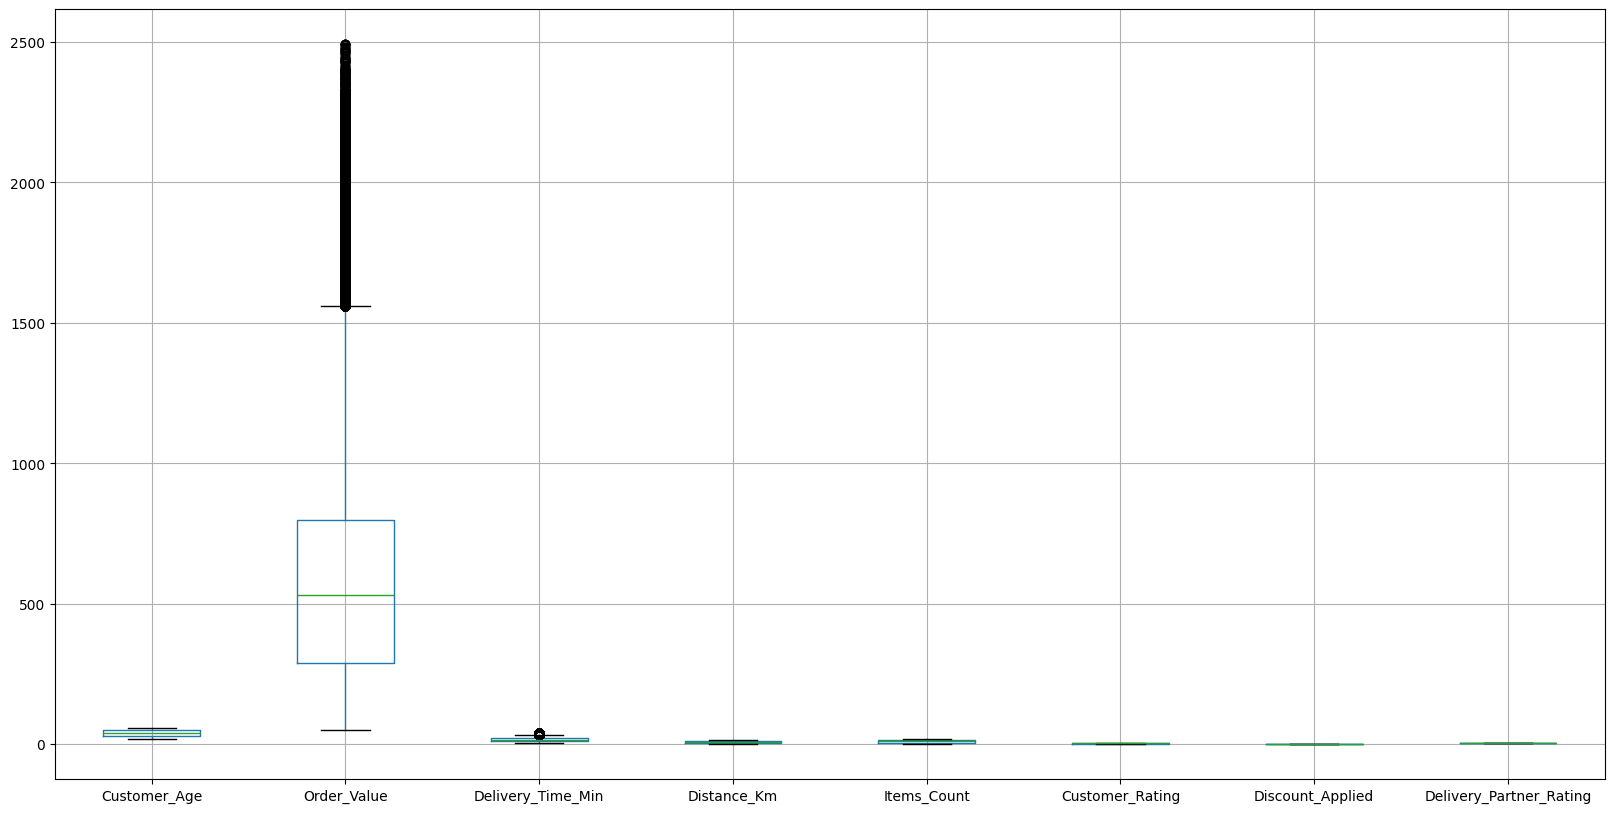

In [23]:
plt.figure(figsize=(20,10))

df.drop(columns=['Order_ID']).boxplot()
plt.show()

In [24]:
df.describe()

,Order_ID,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
count,9.477520e+05,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000,947752.000000
mean,1.500028e+06,38.471165,570.912385,16.502070,7.750046,10.313292,3.042843,0.400786,3.749173
std,2.887273e+05,12.118982,374.174789,6.330106,4.186990,5.630770,1.161112,0.490058,0.684365
min,1.000001e+06,18.000000,50.000000,5.000000,0.500000,1.000000,1.000000,0.000000,2.500000
25%,1.249939e+06,28.000000,287.923000,12.362000,4.130000,5.000000,2.100000,0.000000,3.200000
50%,1.500026e+06,38.000000,531.674100,16.384000,7.750000,10.000000,3.015637,0.000000,3.753051
75%,1.750145e+06,49.000000,796.556650,20.302000,11.380000,15.000000,4.000000,1.000000,4.300000
max,2.000000e+06,59.000000,2492.435250,40.000000,15.000000,19.000000,5.000000,1.000000,5.000000


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 947752 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 947752 non-null  int64  
 1   Company                  947752 non-null  object 
 2   City                     947752 non-null  object 
 3   Customer_Age             947752 non-null  int64  
 4   Order_Value              947752 non-null  float64
 5   Delivery_Time_Min        947752 non-null  float64
 6   Distance_Km              947752 non-null  float64
 7   Items_Count              947752 non-null  float64
 8   Product_Category         947752 non-null  object 
 9   Payment_Method           947752 non-null  object 
 10  Customer_Rating          947752 non-null  float64
 11  Discount_Applied         947752 non-null  int64  
 12  Delivery_Partner_Rating  947752 non-null  float64
dtypes: float64(6), int64(3), object(4)
memory usage: 101.2+ MB


In [26]:
# change data types

df = df.copy()

df.loc[:, 'Order_ID'] = df['Order_ID'].astype(str)
df.loc[:, 'Delivery_Time_Min'] = np.round(df['Delivery_Time_Min'])
df.loc[:, 'Distance_Km'] = np.round(df['Distance_Km'])
df.loc[:, 'Customer_Rating'] = np.round(df['Customer_Rating'])
df.loc[:, 'Delivery_Partner_Rating'] = np.round(df['Delivery_Partner_Rating'])



/tmp/ipykernel_9524/503922248.py:5: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['1000001' '1000002' '1000003' ... '1999998' '1999999' '2000000']' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.loc[:, 'Order_ID'] = df['Order_ID'].astype(str)


In [27]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702.3375,19.0,12.0,12.0,Dairy,Wallet,2.0,1,3.0
1,1000002,Flipkart Minutes,Amritsar,56,1007.3000,20.0,13.0,10.0,Snacks,Cash on Delivery,2.0,0,3.0


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 947752 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 947752 non-null  object 
 1   Company                  947752 non-null  object 
 2   City                     947752 non-null  object 
 3   Customer_Age             947752 non-null  int64  
 4   Order_Value              947752 non-null  float64
 5   Delivery_Time_Min        947752 non-null  float64
 6   Distance_Km              947752 non-null  float64
 7   Items_Count              947752 non-null  float64
 8   Product_Category         947752 non-null  object 
 9   Payment_Method           947752 non-null  object 
 10  Customer_Rating          947752 non-null  float64
 11  Discount_Applied         947752 non-null  int64  
 12  Delivery_Partner_Rating  947752 non-null  float64
dtypes: float64(6), int64(2), object(5)
memory usage: 101.2+ MB


In [29]:
df['Order_Value']= df['Order_Value'].astype(int)
df['Delivery_Time_Min']= df['Delivery_Time_Min'].astype(int)
df['Items_Count']= df['Items_Count'].astype(int)
df['Customer_Rating']= df['Customer_Rating'].astype(int)
df['Delivery_Partner_Rating']= df['Delivery_Partner_Rating'].astype(int)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 947752 entries, 0 to 999999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Order_ID                 947752 non-null  object 
 1   Company                  947752 non-null  object 
 2   City                     947752 non-null  object 
 3   Customer_Age             947752 non-null  int64  
 4   Order_Value              947752 non-null  int64  
 5   Delivery_Time_Min        947752 non-null  int64  
 6   Distance_Km              947752 non-null  float64
 7   Items_Count              947752 non-null  int64  
 8   Product_Category         947752 non-null  object 
 9   Payment_Method           947752 non-null  object 
 10  Customer_Rating          947752 non-null  int64  
 11  Discount_Applied         947752 non-null  int64  
 12  Delivery_Partner_Rating  947752 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 101.2+ MB


In [31]:
df.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1211,17,5.0,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.0,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.0,13,Household,Wallet,4,0,5


In [32]:
# save the file in system

# new_path =r"C:\Users\aravinda.k\OneDrive - Bandhan Technologies Private Limited\Desktop\Projects\Python\Q-Commerce Data Analysis With Python/quick_commerce_modified_data_raw.csv"

In [33]:
# df.to_csv(new_path, index=False)

In [34]:
# load the modified data

# from google.colab import files

# uploaded= files.upload()

In [35]:
# data = pd.read_csv("quick_commerce_modified_data_raw.csv")

In [36]:
df.head()

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3
2,1000003,Flipkart Minutes,Mumbai,18,1211,17,5.0,19,Personal Care,Cash on Delivery,3,0,4
3,1000004,Swiggy Instamart,Delhi,23,1179,6,6.0,2,Dairy,Credit Card,5,1,5
4,1000005,Dunzo,Mumbai,44,586,12,2.0,13,Household,Wallet,4,0,5


# **Business Questions**
# Q 1) Which Q-commerce Platform has the highest total revenue

In [37]:
Company_revenue=df.groupby('Company')['Order_Value'].sum()

In [38]:
Company_revenue.sort_values()

,Order_Value
Company,
Jio Mart,57059272
Dunzo,63953734
Amazon Now,65778875
Flipkart Minutes,66944768
Big Basket,67830915
Zepto,70285754
Blinkit,72445450
Swiggy Instamart,76353684


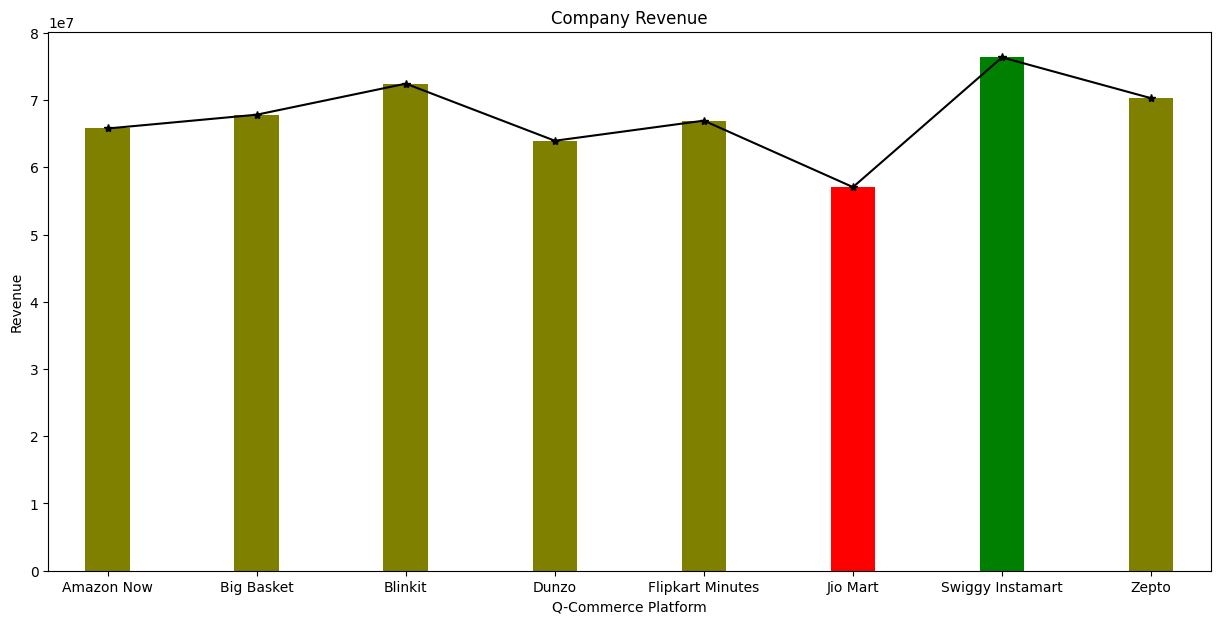

In [44]:
plt.figure(figsize=(15, 7))
max_val=Company_revenue.max()
min_val=Company_revenue.min()
# Assign colors to bars
colors =['green' if val == max_val else 'red' if val==min_val else "olive" for val in Company_revenue]
Company_revenue.plot(kind='bar',color=colors,width=0.3)
Company_revenue.plot(kind='line',color='black',marker="*")
plt.xlabel('Q-Commerce Platform')
plt.ylabel('Revenue')
plt.title('Company Revenue')
plt.show()

# 2) Which Platform has the highest AVG order value.

In [46]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3


In [47]:
AVG_order_value=df.groupby('Company')['Order_Value'].mean().sort_values()
AVG_order_value

,Order_Value
Company,
Jio Mart,482.461481
Dunzo,539.862522
Amazon Now,557.056266
Flipkart Minutes,562.726583
Big Basket,574.609393
Zepto,592.803559
Blinkit,609.363934
Swiggy Instamart,644.470850


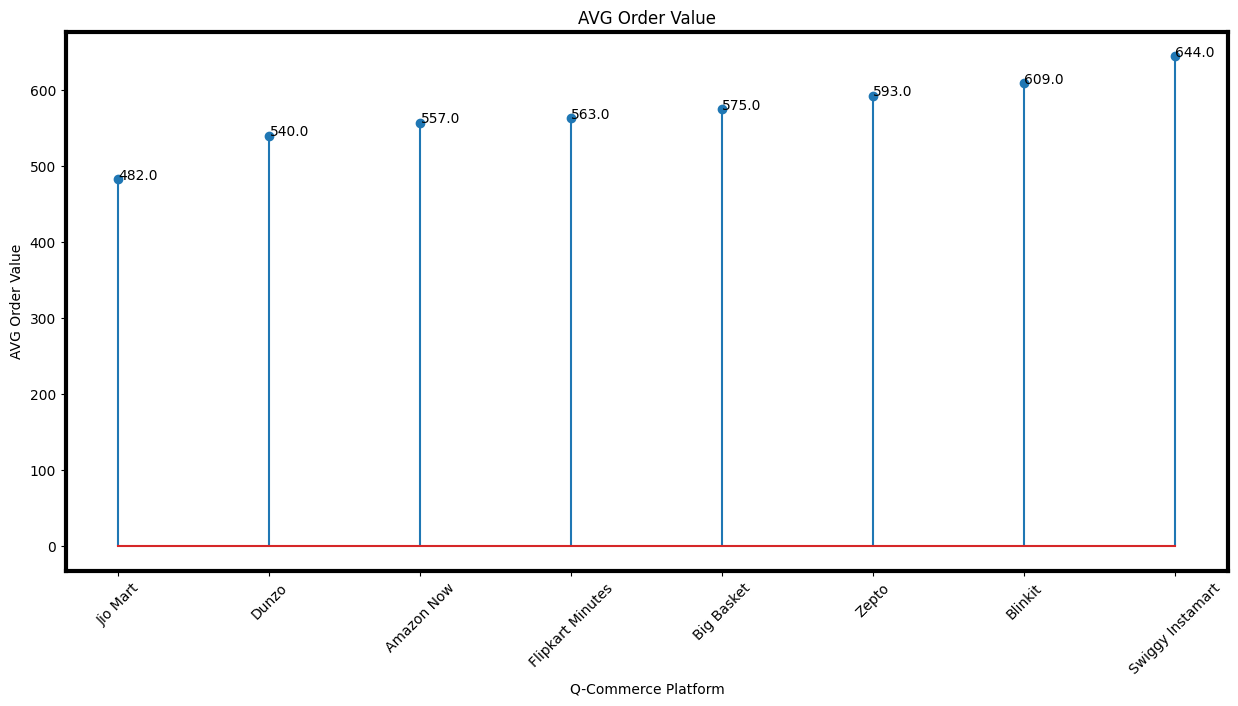

In [53]:
# Stem Chart

plt.figure(figsize=(15, 7))

plt.stem(AVG_order_value.index, AVG_order_value.values)

for x, y in zip(AVG_order_value.index, AVG_order_value.values):
    plt.text(x, y, round(y, 0))

plt.xticks(rotation=45)
plt.xlabel('Q-Commerce Platform')
plt.ylabel('AVG Order Value')
plt.title('AVG Order Value')
ax= plt.gca()
# hightlight all boards
ax.spines['top'].set_linewidth(3)
ax.spines['bottom'].set_linewidth(3)
ax.spines['left'].set_linewidth(3)
ax.spines['right'].set_linewidth(3)
plt.show()

# 3) How Dose Customers Rating is Verying from Platforms

In [54]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3


In [55]:
AVG_Customer_Rating =df.groupby('Company')['Customer_Rating'].mean().sort_values()
AVG_Customer_Rating

,Customer_Rating
Company,
Dunzo,2.428024
Jio Mart,2.819747
Amazon Now,2.913417
Flipkart Minutes,3.016316
Big Basket,3.097902
Zepto,3.203062
Swiggy Instamart,3.279443
Blinkit,3.580762


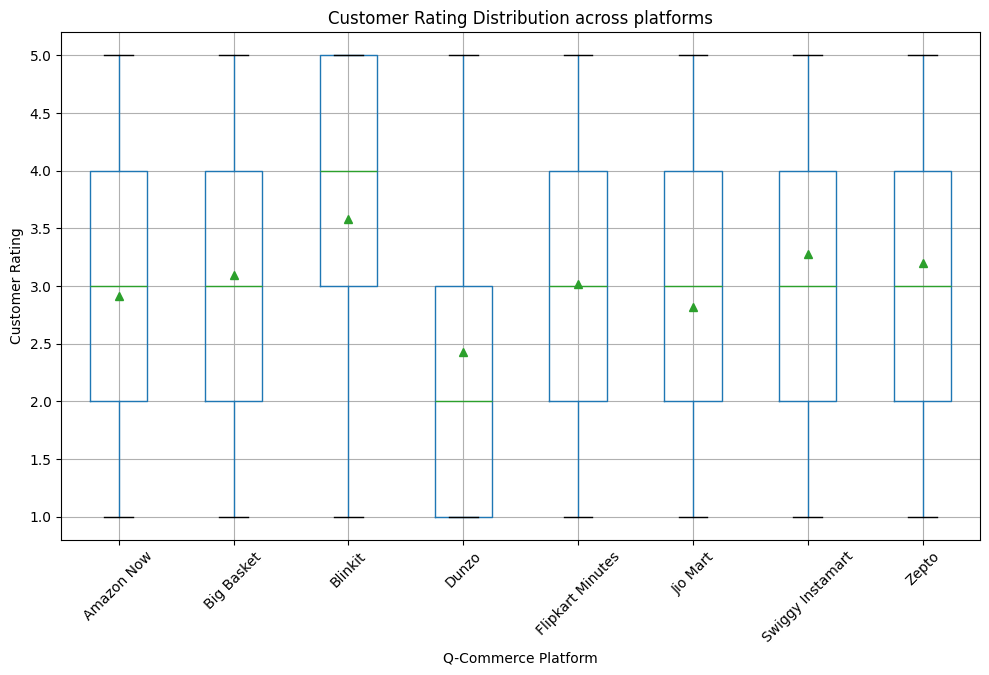

In [79]:
# Box Plot

df.boxplot(column='Customer_Rating', by='Company',showmeans=True,figsize=(10,7))

plt.xlabel('Q-Commerce Platform')
plt.ylabel('Customer Rating')
plt.title('Customer Rating Distribution across platforms')
plt.suptitle('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [85]:
grouped_rating=df.groupby(['Company','Customer_Rating']).size().unstack(fill_value=0)
grouped_rating

Customer_Rating,1,2,3,4,5
Company,,,,,
Amazon Now,15977,30351,30866,29697,11192
Big Basket,10143,30339,31020,30908,15637
Blinkit,1060,25553,25561,36708,30005
Dunzo,29818,36280,25377,25818,1170
Flipkart Minutes,12549,30786,31225,30985,13420
Jio Mart,18513,30515,31083,30089,8067
Swiggy Instamart,5000,30278,31039,30931,21227
Zepto,7618,29763,31367,30559,19258


<Figure size 2500x2500 with 0 Axes>

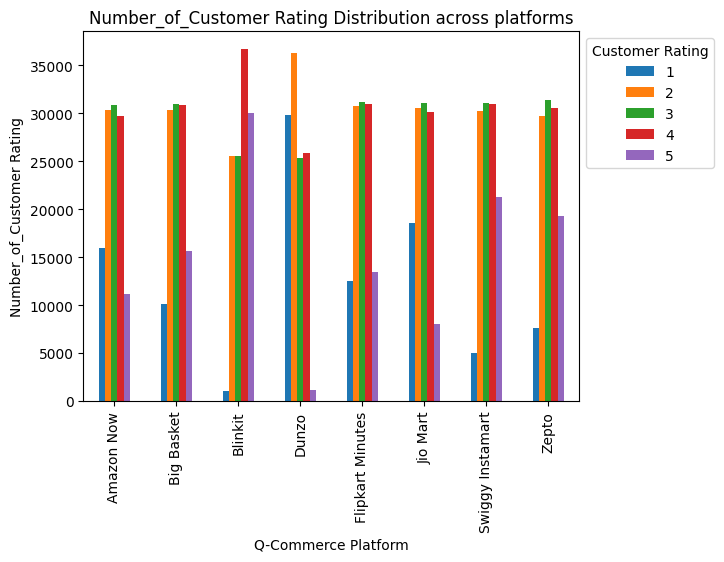

In [107]:
from matplotlib.transforms import Bbox
plt.figure(figsize=(25,25))
grouped_rating.plot(kind='bar')
plt.xlabel('Q-Commerce Platform')
plt.ylabel('Number_of_Customer Rating')
plt.title('Number_of_Customer Rating Distribution across platforms')
plt.legend(title='Customer Rating', bbox_to_anchor =(1,1),loc="upper left")
plt.show()

# 4) Dose Delivery time affects the "Delivery Partner Rating"

In [108]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3


In [109]:
df['Delivery_Time_Min'].mean()

np.float64(16.506619875241626)

In [110]:
df['Delivery_Partner_Rating'].mean()

np.float64(3.80029480285982)

In [114]:
x=df.groupby('Delivery_Time_Min')['Delivery_Partner_Rating'].mean()
x

,Delivery_Partner_Rating
Delivery_Time_Min,
5,3.803956
6,3.798555
7,3.805901
8,3.803807
9,3.804469
10,3.801688
11,3.799953
12,3.798843
13,3.795841


In [112]:
df['Delivery_Time_Min'].corr(df['Delivery_Partner_Rating'])

np.float64(-0.002777340802669754)

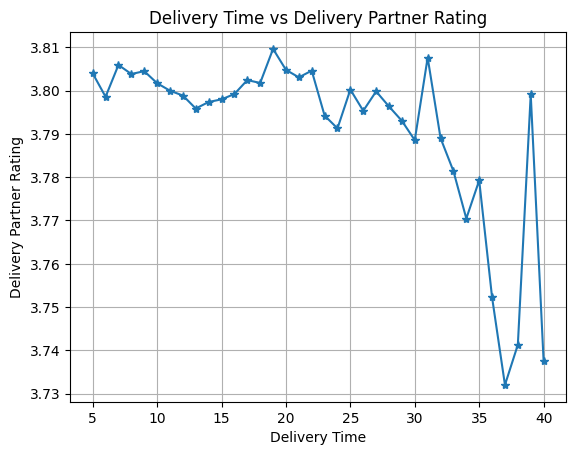

In [120]:
# line chart
x.plot(kind='line',marker="*")
plt.grid()
plt.xlabel('Delivery Time')
plt.ylabel('Delivery Partner Rating')
plt.title('Delivery Time vs Delivery Partner Rating')
plt.show()

# What is the Most Popular product Category on swiggy instamart, for the people age between 30 to 40 in mumbia.

In [121]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3


In [128]:
Swiggy_Instamart= df[(df['Company']=='Swiggy Instamart') &
                  (df['City']=='Mumbai') &
                  ((df['Customer_Age']>=30) & (df['Customer_Age']<40))]


In [129]:
Swiggy_Instamart['Product_Category'].value_counts().sort_values()

,count
Product_Category,
Beverages,299
Personal Care,305
Snacks,329
Household,340
Groceries,341
Fruits & Vegetables,343
Dairy,368


# 6) Are Discounts increasing  order volume or just reeduing revenue?



In [130]:
df.head(2)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3
1,1000002,Flipkart Minutes,Amritsar,56,1007,20,13.0,10,Snacks,Cash on Delivery,2,0,3


In [132]:
# Count of orders for Discount_Applied

df['Discount_Applied'].value_counts()

,count
Discount_Applied,
0,567906
1,379846


In [135]:
# Calculate AVG Order value

Dis_AVG_Order_value = df.groupby('Discount_Applied')['Order_Value'].mean()
Dis_AVG_Order_value

,Order_Value
Discount_Applied,
0,475.965137
1,711.733163


In [147]:
# Calculate sum of items counts

dis_items_count=df.groupby('Discount_Applied')['Items_Count'].mean()

dis_items_count

,Items_Count
Discount_Applied,
0,10.308498
1,10.320459


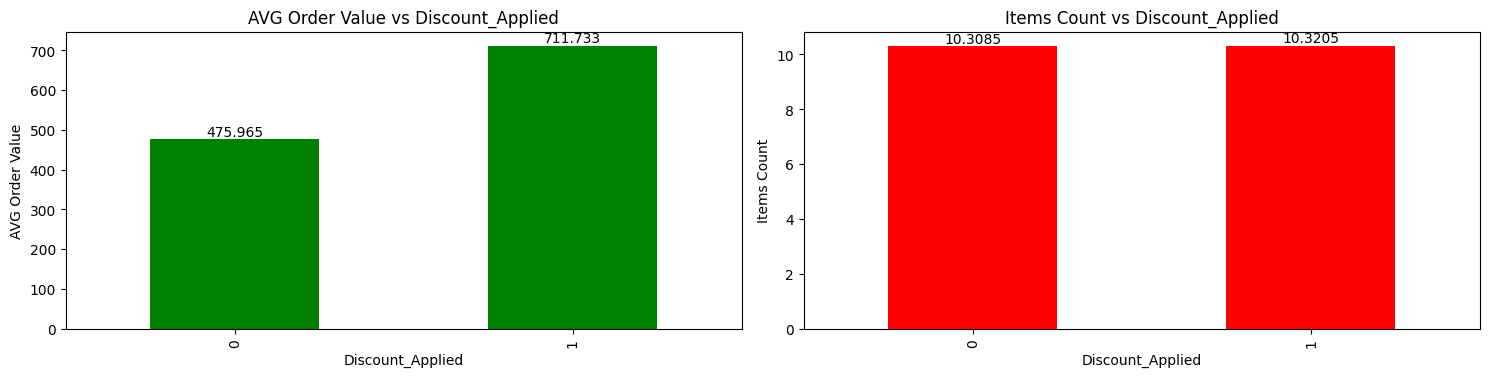

In [155]:
plt.figure(figsize=(15,7))

plt.subplot(2,2,1)
Dis_AVG_Order_value.plot(kind='bar', color='g')
plt.bar_label(plt.gca().containers[0])
plt.xlabel('Discount_Applied')
plt.ylabel('AVG Order Value')
plt.title('AVG Order Value vs Discount_Applied')
plt.subplot(2,2,2)
dis_items_count.plot(kind='bar', color='r')
plt.bar_label(plt.gca().containers[0])
plt.xlabel('Discount_Applied')
plt.ylabel('Items Count')
plt.title('Items Count vs Discount_Applied')
plt.tight_layout()
plt.show()

# 7)Which Company has the best operational efficiency (Delivery time Vs Order volumne)

In [158]:
df.head(1)

,Order_ID,Company,City,Customer_Age,Order_Value,Delivery_Time_Min,Distance_Km,Items_Count,Product_Category,Payment_Method,Customer_Rating,Discount_Applied,Delivery_Partner_Rating
0,1000001,Swiggy Instamart,Noida,46,702,19,12.0,12,Dairy,Wallet,2,1,3


In [162]:
df.groupby('Company').agg(
                           total_orders= ('Order_ID',"count"),
                           AVG_Delivey_time= ('Delivery_Time_Min',"mean"),
                           AVG_Order_Value= ('Order_Value',"mean")).reset_index()

,Company,total_orders,AVG_Delivey_time,AVG_Order_Value
0,Amazon Now,118083,18.984155,557.056266
1,Big Basket,118047,18.027345,574.609393
2,Blinkit,118887,15.121771,609.363934
3,Dunzo,118463,14.177060,539.862522
4,Flipkart Minutes,118965,17.045080,562.726583
5,Jio Mart,118267,23.013224,482.461481
6,Swiggy Instamart,118475,16.072690,644.470850
7,Zepto,118565,9.644313,592.803559
